In [1]:
%pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, glob, time
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog, local_binary_pattern
from skimage.feature import hog, local_binary_pattern

ROOT = "Tobacco3482-jpg"
paths  = sorted(glob.glob(ROOT + "/*/*.jpg"))
labels = np.array([os.path.basename(os.path.dirname(p)) for p in paths])

print(len(paths), "images")
for c in np.unique(labels):
    print(f"{c:11s}", (labels == c).sum())

3482 images
ADVE        230
Email       599
Form        431
Letter      567
Memo        620
News        188
Note        201
Report      265
Resume      120
Scientific  261


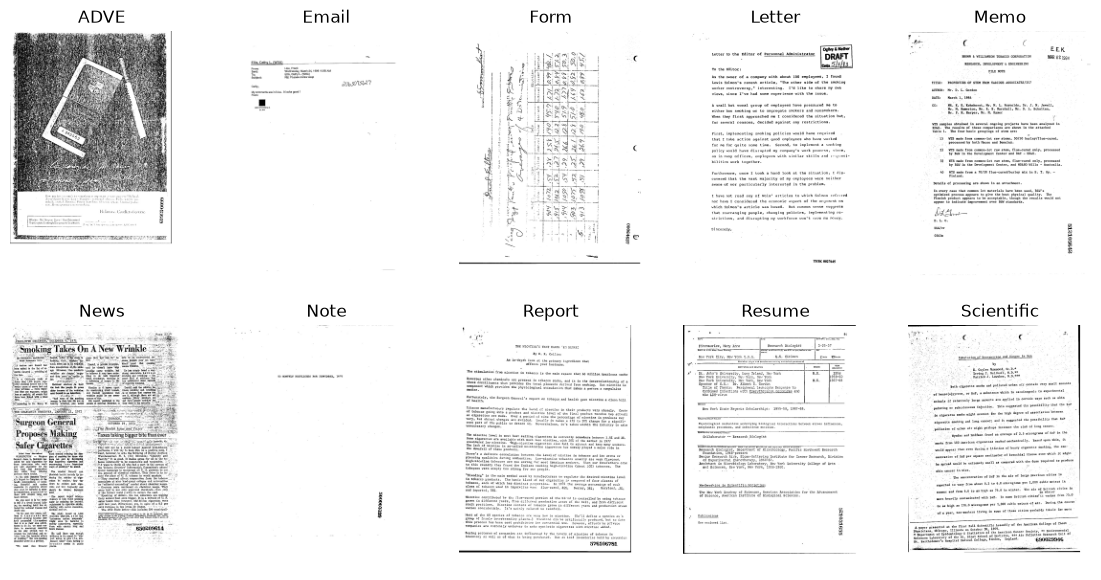

In [3]:
H, W = 256, 192

def load(p):
    g = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    return cv2.resize(g, (W, H), interpolation=cv2.INTER_AREA)

def binarize(g):
    _, b = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return b // 255          # 1 = encre, 0 = fond

fig, ax = plt.subplots(2, 5, figsize=(14, 7))
for a, c in zip(ax.ravel(), np.unique(labels)):
    a.imshow(load(paths[np.where(labels == c)[0][0]]), cmap="gray")
    a.set_title(c); a.axis("off")
plt.show()

In [4]:
def f_layout(g):    # miniature 16x12 : disposition globale
    return cv2.resize(g, (12, 16), interpolation=cv2.INTER_AREA).flatten() / 255.

def f_density(b, n=8, m=6):    # densité d'encre par zone
    return cv2.resize(b.astype(np.float32), (m, n), interpolation=cv2.INTER_AREA).flatten()

def f_proj(b):    # profils de projection horizontal et vertical
    h = cv2.resize(b.mean(1).reshape(-1, 1).astype(np.float32), (1, 32), interpolation=cv2.INTER_AREA).flatten()
    v = cv2.resize(b.mean(0).reshape(1, -1).astype(np.float32), (32, 1), interpolation=cv2.INTER_AREA).flatten()
    return np.concatenate([h, v])

def f_hog(g):    # forme : orientation des contours
    return hog(g, orientations=9, pixels_per_cell=(32, 32),
               cells_per_block=(2, 2), feature_vector=True)

def f_lbp(g):    # texture
    l = local_binary_pattern(g, 8, 1, "uniform")
    h, _ = np.histogram(l, bins=10, range=(0, 10))
    return h / h.sum()

def f_edges(g):    # orientation des contours (lignes de formulaires)
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0); gy = cv2.Sobel(g, cv2.CV_32F, 0, 1)
    mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    h, _ = np.histogram(ang % 180, bins=12, range=(0, 180), weights=mag)
    return h / (h.sum() + 1e-9)

DESC = {"layout": lambda g, b: f_layout(g), "density": lambda g, b: f_density(b),
        "proj":   lambda g, b: f_proj(b),   "hog":     lambda g, b: f_hog(g),
        "lbp":    lambda g, b: f_lbp(g),    "edges":   lambda g, b: f_edges(g)}

In [5]:

t = time.time()
F = {k: [] for k in DESC}
for p in paths:
    g = load(p); b = binarize(g)
    for k, f in DESC.items():
        F[k].append(f(g, b))
F = {k: np.array(v) for k, v in F.items()}

print(f"Indexation : {time.time() - t:.1f} s")
for k, v in F.items(): print(k, v.shape)

Indexation : 258.3 s
layout (3482, 192)
density (3482, 48)
proj (3482, 64)
hog (3482, 1260)
lbp (3482, 10)
edges (3482, 12)


In [6]:
def zscore(X):
    return (X - X.mean(0)) / (X.std(0) + 1e-9)

def combine(keys):
    blocks = []
    for k in keys:
        Z = zscore(F[k])
        blocks.append(Z / np.sqrt(Z.shape[1]))   # chaque descripteur pèse autant
    return np.hstack(blocks)

In [7]:
def dist_matrix(X, metric="cosine"):
    if metric == "cosine":
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)
        return 1 - Xn @ Xn.T
    sq = (X**2).sum(1)
    return np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * X @ X.T, 0))

def search(q_idx, D, k=5):
    d = D[q_idx].copy(); d[q_idx] = np.inf     # exclure la requête elle-même
    return np.argsort(d)[:k]

def show_results(q_idx, D, k=5):
    res = search(q_idx, D, k)
    fig, ax = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 4.5))
    ax[0].imshow(load(paths[q_idx]), cmap="gray")
    ax[0].set_title(f"REQUÊTE\n{labels[q_idx]}", color="blue")
    for a, r in zip(ax[1:], res):
        a.imshow(load(paths[r]), cmap="gray")
        a.set_title(f"{labels[r]}\nd={D[q_idx, r]:.3f}",
                    color="green" if labels[r] == labels[q_idx] else "red")
    for a in ax: a.axis("off")
    plt.show()

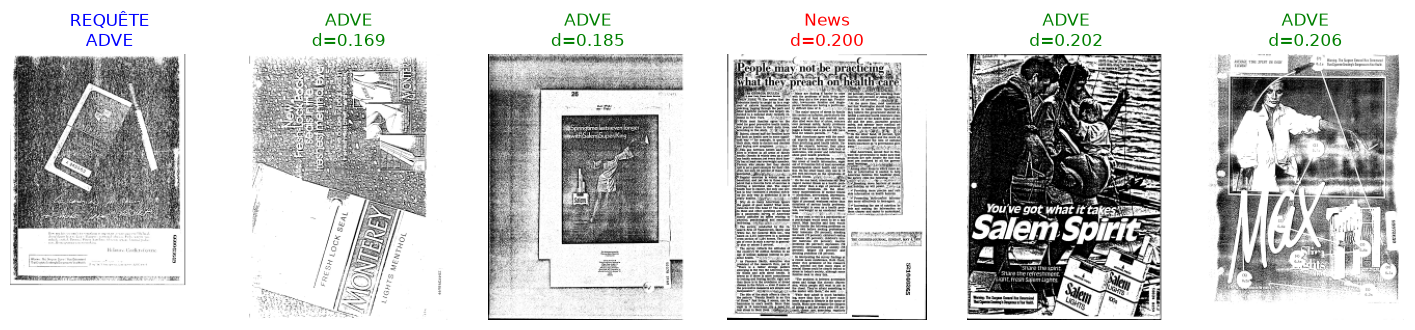

In [8]:
D_final = dist_matrix(combine(list(F)), "cosine")
idx = np.where(labels == "ADVE")[0][0]
show_results(idx, D_final, k=5)

In [9]:
def evaluate(D, labels, ks=(1, 5, 10)):
    n = len(labels); D = D.copy(); np.fill_diagonal(D, np.inf)
    order = np.argsort(D, 1)[:, :n - 1]
    rel = (labels[order] == labels[:, None])
    res = {f"P@{k}": rel[:, :k].mean() for k in ks}
    prec = np.cumsum(rel, 1) / np.arange(1, n)
    res["mAP"] = ((prec * rel).sum(1) / np.maximum(rel.sum(1), 1)).mean()
    return res

rows = {}
for k in F:
    X = zscore(F[k]) if k != "lbp" else F[k]
    for m in ["euclid", "cosine"]:
        rows[f"{k} ({m})"] = evaluate(dist_matrix(X, m), labels)
for name, keys in {"hog+layout": ["hog", "layout"], "TOUS": list(F)}.items():
    for m in ["euclid", "cosine"]:
        rows[f"{name} ({m})"] = evaluate(dist_matrix(combine(keys), m), labels)

res = pd.DataFrame(rows).T.round(3)
print("Baseline aléatoire ≈", round((labels == "Letter").mean(), 3))
res.sort_values("mAP", ascending=False)

Baseline aléatoire ≈ 0.163


,P@1,P@5,P@10,mAP
TOUS (cosine),0.675,0.624,0.593,0.347
hog+layout (cosine),0.681,0.616,0.583,0.346
hog (cosine),0.650,0.584,0.553,0.329
TOUS (euclid),0.667,0.611,0.576,0.326
hog+layout (euclid),0.617,0.551,0.516,0.305
layout (cosine),0.580,0.515,0.482,0.289
hog (euclid),0.588,0.518,0.485,0.287
layout (euclid),0.584,0.522,0.490,0.280
density (euclid),0.571,0.517,0.488,0.278
density (cosine),0.551,0.490,0.460,0.273


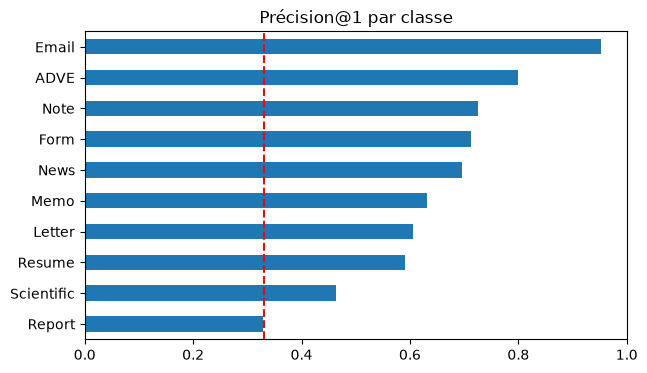

In [10]:
D = D_final.copy(); np.fill_diagonal(D, np.inf)
nn = D.argmin(1)
acc = pd.Series({c: (labels[nn] == labels)[labels == c].mean()
                 for c in np.unique(labels)}).sort_values()
acc.plot.barh(figsize=(7, 4), title="Précision@1 par classe")
plt.axvline(0.33, color="r", ls="--"); plt.show()